## Do the same as in ISPRS-modalities-analysis, but give the appropriate tabular data as well

In [200]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

In [201]:
wandb_id = 'fuvmj0ci'


In [202]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()

# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [203]:
country_name_mapping = {
    "Vietnam" : "Viet Nam",
    "Tanzania" : "United Republic of Tanzania",
    "Dem. Rep. Congo" : "Democratic Republic of the Congo",
    "Dominican Rep." : "Dominican Republic",
    "Bolivia" : "Bolivia (Plurinational State of)",
    "Venezuela" : "Venezuela (Bolivarian Republic of)",
    "Central African Rep.": "Central African Republic",
    "Eq. Guinea" : "Equatorial Guinea",
    "eSwatini" : "Eswatini",
    "Laos" : "Lao People's Democratic Republic",
    "Taiwan" : "China, Taiwan Province of",
    "Brunei" : "Brunei Darussalam",
    "S. Sudan" : "South Sudan",
    "Solomon Is." : "Solomon Islands"
}

#Add country name
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

min_lon = -180
max_lon = 180
min_lat = -30
max_lat = 30
tropics = Polygon([(min_lon, min_lat), (min_lon, max_lat), (max_lon, max_lat, ), (max_lon, min_lat )])
tropical_countries = world.loc[world.intersects(tropics)]



/tmp/ipykernel_106135/590309720.py:19: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


In [204]:
def find_intersections_or_nearest(gdf_points, gdf_polygons):
    """
    For each point in gdf_points, find which polygon it intersects with. 
    If it doesn't intersect any polygon, find the closest polygon.
    
    Parameters:
    gdf_points (GeoDataFrame): A GeoDataFrame containing points.
    gdf_polygons (GeoDataFrame): A GeoDataFrame containing polygons.
    
    Returns:
    GeoDataFrame: A GeoDataFrame of points with a new column 'nearest_or_intersecting_polygon' indicating the index of the intersecting or nearest polygon.
    """
    # Initialize a column to store the index of the nearest or intersecting polygon
    gdf_points['country'] = None
    
    for point_index, point_row in gdf_points.iterrows():
        # Check for intersections first
        intersects = gdf_polygons.intersects(point_row.geometry)
        if intersects.any():
            # If there's an intersection, use the first intersecting polygon
            idx = intersects.idxmax()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[idx]['name']
        else:
            # Find the nearest polygon if no intersection
            # Calculate the nearest points between the current point and all polygons, then find the minimum
            distances = gdf_polygons.geometry.apply(lambda poly: point_row.geometry.distance(nearest_points(point_row.geometry, poly)[1]))
            nearest_polygon_index = distances.idxmin()
            gdf_points.at[point_index, 'country'] = gdf_polygons.iloc[nearest_polygon_index]['name']
    
    return gdf_points

In [153]:
def add_country_names(gdf, country_name_mapping=country_name_mapping):

    gdf = gpd.sjoin(gdf, tropical_countries[['geometry', 'name']], how='left', predicate='within')[['geometry', 'driver', 'sampleid', 'dataset', 'name']]
    gdf['country'] = gdf['name']
    gdf = gdf.drop('name', axis=1)


    names_to_edit = [key for key in country_name_mapping.keys()]
    for name in names_to_edit:
        gdf.loc[gdf['country'] == name, 'country'] = country_name_mapping[name]

    return gdf

In [165]:

def generate_random_points_df(df, land_areas=land_areas, n_points=1000):

    # Create initial DataFrame with one row
    #df = pd.DataFrame(data)

    # Function to generate random points within the land mask
    def generate_random_point_within_land(land_areas):
        while True:
            # Generate random latitude and longitude within the tropics
            random_lat = random.uniform(-23.5, 23.5)
            random_lon = random.uniform(-180, 180)
            point = Point(random_lon, random_lat)


            # Check if point lies within land area
            for land_area in land_areas.geometry:
                if land_area.contains(point):
                    return point

    # Create a list of random points for 10,000 rows
    new_data = []
    for _ in tqdm.tqdm(range(n_points)):
        # Generate random land point
        random_point = generate_random_point_within_land(land_areas.geometry)
        row = df.iloc[0].copy()  # Copy the row template
        row['geometry'] = random_point  # Assign the new random point as geometry
        new_data.append(row)

    # Create a new DataFrame with 10,000 rows
    new_df = pd.DataFrame(new_data)
    new_df = new_df.reset_index(drop=True)

    return new_df


def predict(model, dataloader):
    
    model.eval()

    preds_batches = []
    targets_batches = []

    for data_batch, labels_batch in dataloader:

        image_batch, loc_batch, expansion_rates_batch, forestloss_batch, labels_batch = data_batch[0].to(device), data_batch[1].to(device), data_batch[2].to(device), data_batch[3].to(device), labels_batch.to(device)
        y_hat = model(image_batch, loc_batch, expansion_rates_batch, forestloss_batch)


        y_hat = F.softmax(y_hat, dim=1)
        y_hat = y_hat.cpu().detach()
        labels_batch = labels_batch.cpu().detach()

        preds_batches.append(y_hat)
        targets_batches.append(labels_batch)
        
    probabilities = torch.cat(preds_batches, axis=0).cpu().detach()

    preds = probabilities.argmax(dim=1).numpy()
    
    return probabilities.numpy(), preds

In [166]:
forestloss_dir = '../../Vancutsem_yearloss'
tmf_extent = get_tiles_as_gdf(forestloss_dir)
tmf_extent.crs = 4326


# Load a land mask (for simplicity, this can be a GeoDataFrame of the world land mask)
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# Filter world data to only include land areas
land_areas = gpd.overlay(world, tmf_extent, how='intersection')

/tmp/ipykernel_106135/1446822280.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_106135/1446822280.py:9: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  land_areas = gpd.overlay(world, tmf_extent, how='intersection')


In [167]:
def write_annotation_file(sampleid, val_dl, out_path, points=1000):

    single_row_df = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == sampleid])
    single_row_df = single_row_df.reset_index(drop=True)
    _df = generate_random_points_df(single_row_df,n_points=points)
    gdf = gpd.GeoDataFrame(_df)
    gdf.crs = 4326    
    gdf = add_country_names(gdf)
    gdf['split'] = 4
    pd.DataFrame(gdf).to_csv(f'../data/tmp/{out_file}.csv', index=False)
    gdf.to_file(f'../data/tmp/{out_file}.gpkg')


## Urban

In [130]:
_sampleid = 100005898
out_file = 'urban'

cls_index = 6

In [117]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 144.66it/s]


In [133]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']

probabilities, preds = predict(model, cls_val_dl)


In [134]:
gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')

In [135]:
gdf['preds'] = preds
gdf['probabilities'] = probabilities[:,cls_index].tolist()

In [137]:
gdf.to_file(f'../data/tmp/{out_file}.gpkg')

## Palm oil 80103253

In [170]:
_sampleid = 80103253
out_file = 'palm_oil'

cls_index = 4



In [171]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 143.71it/s]


In [172]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']

probabilities, preds = predict(model, cls_val_dl)


In [ ]:
gdf

In [173]:
gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')

In [174]:
gdf['preds'] = preds
gdf['probabilities'] = probabilities[:,cls_index].tolist()

In [176]:
gdf.to_file(f'../data/tmp/{out_file}.gpkg')

In [177]:
f'../data/tmp/{out_file}.gpkg'

'../data/tmp/palm_oil.gpkg'

In [ ]:
'''
palm_oil_sampleids = \
    [
        90042955,
        80103253,
        90042963
    ]
'''


## Palm oil 90042955

In [179]:
_sampleid = 90042955
out_file = 'palm_oil_90042955'

cls_index = 4



In [180]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 153.85it/s]


In [181]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']

probabilities, preds = predict(model, cls_val_dl)


In [182]:
gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')
gdf['preds'] = preds
gdf['probabilities'] = probabilities[:,cls_index].tolist()

In [184]:
gdf.to_file(f'../data/tmp/{out_file}.gpkg')

## Soy 10631488

In [187]:
_sampleid = 10631488
out_file = 'soy_10631488'

cls_index = 2



In [188]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 148.10it/s]


In [189]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']

probabilities, preds = predict(model, cls_val_dl)


In [190]:
gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')
gdf['preds'] = preds
gdf['probabilities'] = probabilities[:,cls_index].tolist()

In [192]:
gdf.to_file(f'../data/tmp/{out_file}.gpkg')

## Soy 150103777

In [194]:
#150103777, 10615508

_sampleid = 150103777
out_file = 'soy_150103777'

cls_index = 2



In [195]:
write_annotation_file(_sampleid, val_dl, out_file, 1000)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 144.80it/s]


In [196]:
config['data']['annotation_file'] = f'/home/jan/Documents/EPFL/project_2/data/tmp/{out_file}.csv'
# fetch dataloaders
cls_dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
cls_val_dl = cls_dataloaders['val']

probabilities, preds = predict(model, cls_val_dl)


In [197]:
gdf = gpd.read_file(f'../data/tmp/{out_file}.gpkg')
gdf['preds'] = preds
gdf['probabilities'] = probabilities[:,cls_index].tolist()

In [199]:
gdf.to_file(f'../data/tmp/{out_file}.gpkg')

In [205]:
x,y = next(iter(val_dl))

In [209]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label, figsize=(16,16)):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(figsize[0], figsize[1]))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



3404

driver                               shifting agriculture
sampleid                                        130004771
dataset                    tyukavina_congo_basin_agri.csv
country                                   Dem. Rep. Congo
geometry    POINT (23.392802080826815 -5.036872730749599)
block_id                                            134.0
split                                                 val
dst_size                                              NaN
Name: 1613, dtype: object
shifting agriculture


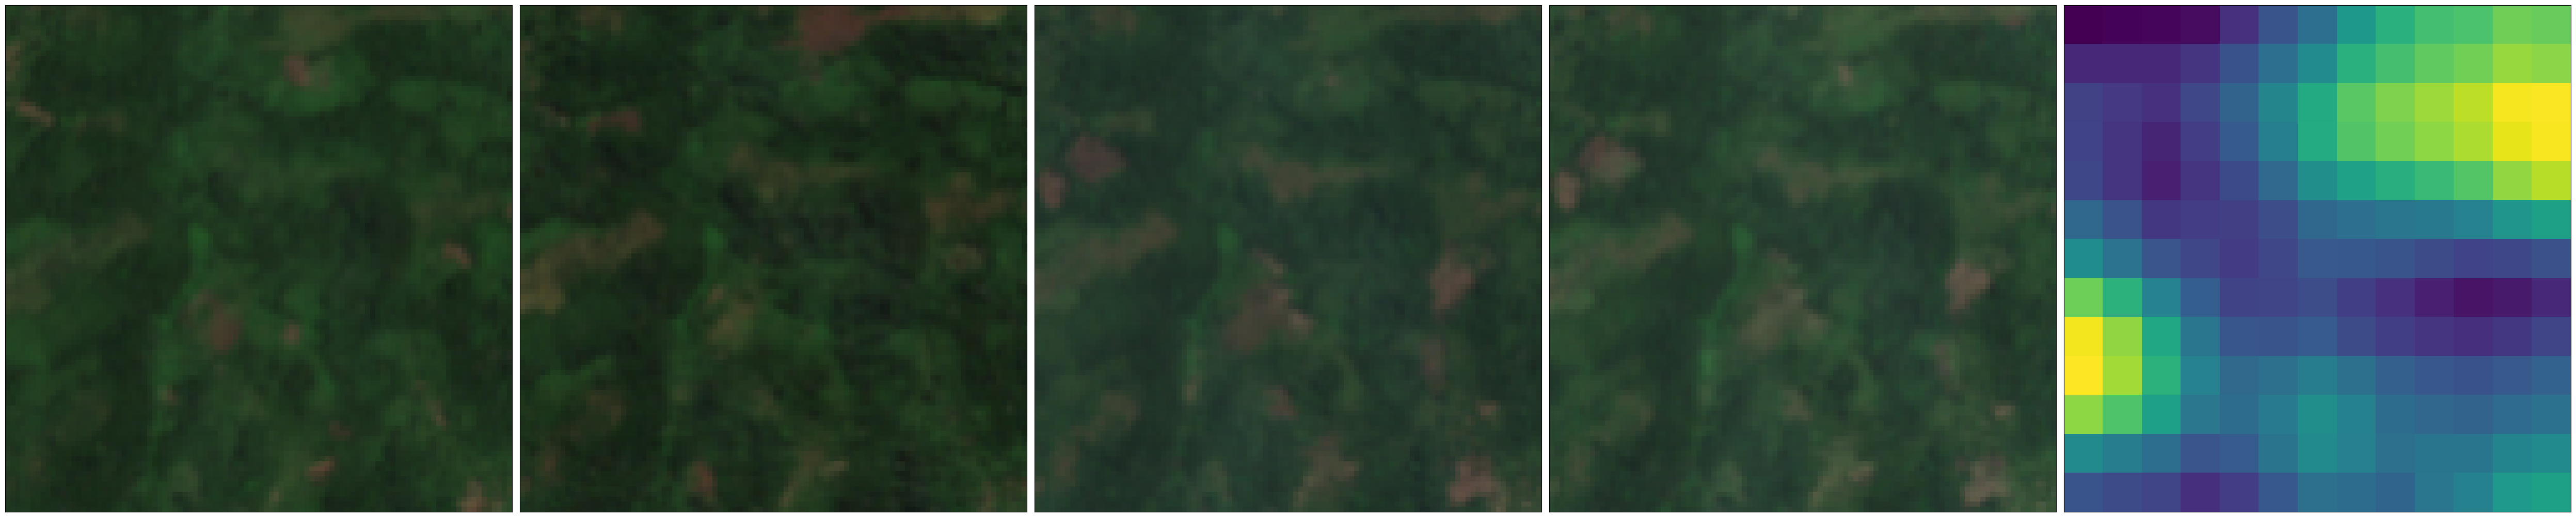

KeyboardInterrupt: Interrupted by user

In [230]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver in ['coffee', 'soy', 'rubber', 'pasture', 'mining', 'palm oil','cocoa' ]:
        continue
        
    idx = row.name

    print(row)
    x, label = val_dl.dataset.__getitem__(idx)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    #pprint.pprint(rates)
    #print()
    #pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label], figsize=(50,15))

    _waitforinput = input()

    clear_output(wait=True)

In [ ]:
#150103777

In [ ]:
soy_sampleid = [
    150103777 #2,3,4
]


In [64]:
sampleids = [
    150103777, #soy
    190000122, # coffee
    20012478, # rubber
    20011327,  # rubber
    10233612, # pasture, would need tmf #10082490 same
    10487199, #pasture
    140022376, #mining
    #80076083, # forest plantation, not 100% 80075269
    80074833, #forest plantation, nice
    100006157, #urban
    80103063, #palm oil indo, ok
    90032710, #palm oil malaysia, better
    #30000593, #cocoa, ok
    #30009296, #cocoa ok #30009243 30001690 30001943
    30006564 # cocoa maybe this one better
    
    
    #130003877, #shifting, could be better #130017084 #130004771
    130004734, #shifting, is ok
    
    80265603, # other, indonesia agriculture
    180000794, # other, bolivia river, may need tmf
    10041328, #other, brazil river, maybe better
    10643721, #other brazil water


]

In [ ]:
preds = []
for _i, row in tqdm.tqdm(df_soy.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(_soy_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

## Generate df with random locations

/tmp/ipykernel_106135/1446822280.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_106135/1446822280.py:9: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  land_areas = gpd.overlay(world, tmf_extent, how='intersection')


### Urban

In [17]:
urban_sampleid = 100005898

In [18]:
urban_sampleid = 100005898
df_urban = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == urban_sampleid])
df_urban = df_urban.reset_index(drop=True)

In [21]:
new_df = generate_random_points_df(df_urban)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 134.11it/s]


In [73]:
gpd.GeoDataFrame(new_df).to_file('../data/tmp/tmp_urban.gpkg')

In [48]:
# here if i want a img-loc model only

'''wandb_id_img_loc = 'l432djh6' #img+loc


model_dir = os.path.join('../models_trained', wandb_id_img_loc)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id_img_loc}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()'''


"wandb_id_img_loc = 'l432djh6' #img+loc\n\n\nmodel_dir = os.path.join('../models_trained', wandb_id_img_loc)\nconfig_path = os.path.join(model_dir, 'config.json')\nwith open(config_path) as source:\n    config = json.loads(source.read())\n\n\n#Load trained model\nmodel = MultiModalDriverClassifier(11,  **config)\nmodel = model.to(device)\n\ntrained_weights = f'../models_trained/{wandb_id_img_loc}/last.pt'\n_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])\n_ = model.eval()"

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


tensor([ 2.9829, 17.0390])
{'cocoa': 0.0,
 'coffee': 0.0,
 'forest plantation': 0.0,
 'mining': 0.0,
 'other': 0.0,
 'palm oil': 0.001,
 'pasture': 0.0,
 'rubber': 0.0,
 'shifting agriculture': 0.002,
 'soy': 0.0,
 'urban': 0.996}
urban


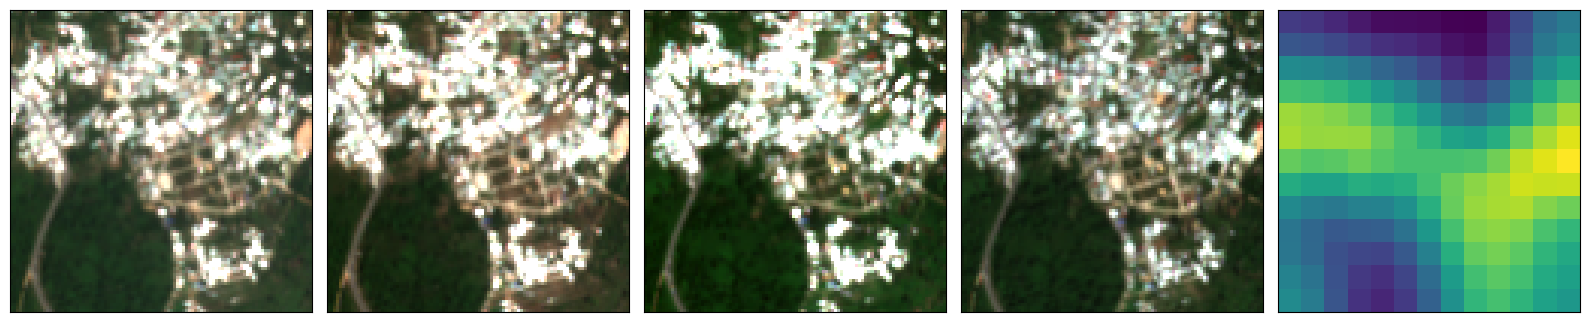

KeyboardInterrupt: Interrupted by user

In [74]:

for _i, row in new_df.iterrows():
    i = row.name
    x, label = val_dl.dataset.__getitem__(817) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    print(loc)
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    #pprint.pprint(rates)
    #print()
    pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)
    
    

In [75]:
preds = []
for _i, row in tqdm.tqdm(new_df.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(817) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

1000it [00:22, 43.71it/s]


In [76]:
new_df['prediction'] = torch.Tensor(np.array(preds)).argmax(dim=1)

In [77]:
new_df['probability'] = torch.Tensor(np.array(preds))[:,6]

In [78]:
gpd.GeoDataFrame(new_df).to_file('../data/tmp/tmp_urban.gpkg')

### Mining 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


driver                                             mining
sampleid                                        140005686
dataset                                         mines.csv
country                                            Brazil
geometry    POINT (-56.29051594558841 -6.098752206155797)
block_id                                             71.0
split                                                 val
dst_size                                              NaN
Name: 1254, dtype: object
{'cocoa': 0.0,
 'coffee': 0.02,
 'forest plantation': 0.06,
 'mining': nan,
 'other': nan,
 'palm oil': 0.0,
 'pasture': 1.75,
 'rubber': 0.0,
 'shifting agriculture': nan,
 'soy': 0.29,
 'urban': nan}

{'cocoa': 0.0,
 'coffee': 0.0,
 'forest plantation': 0.0,
 'mining': 0.991,
 'other': 0.002,
 'palm oil': 0.0,
 'pasture': 0.001,
 'rubber': 0.0,
 'shifting agriculture': 0.0,
 'soy': 0.0,
 'urban': 0.005}
mining


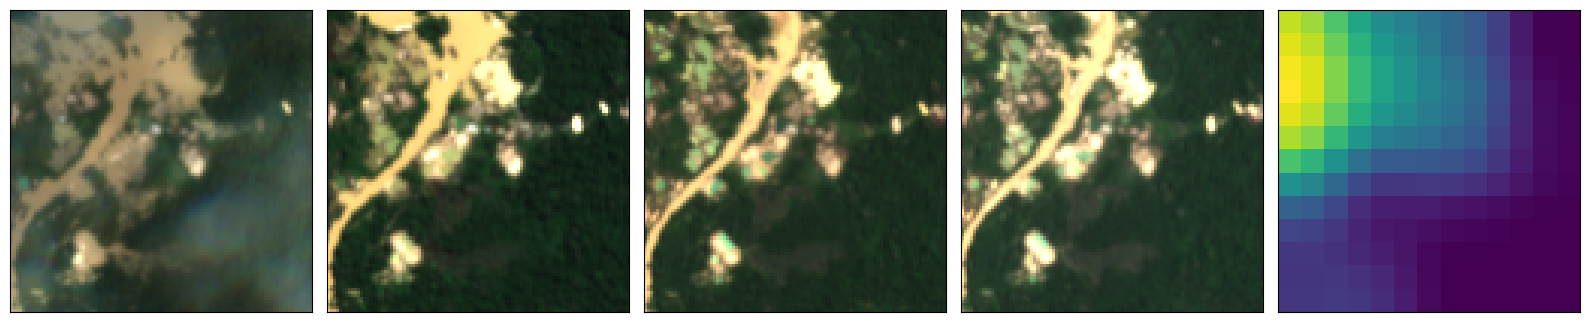

KeyboardInterrupt: Interrupted by user

In [134]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver != 'mining':
        continue
    i = row.name
    print(row)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    pprint.pprint(rates)
    print()
    pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

In [136]:
mining_sampleid = 140005686

In [137]:
_df_mining = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == mining_sampleid])


,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
1254,mining,140005686,mines.csv,Brazil,POINT (-56.29052 -6.09875),71.0,val,NaN


In [139]:
mining_idx = 1254

In [ ]:
_df_mining = _df_mining.reset_index(drop=True)


In [138]:
df_mining = generate_random_points_df(_df_mining)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 140.57it/s]


In [140]:
preds = []
for _i, row in tqdm.tqdm(df_mining.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(mining_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

1000it [00:22, 43.93it/s]


In [141]:
df_mining['prediction'] = torch.Tensor(np.array(preds)).argmax(dim=1)
df_mining['probability'] = torch.Tensor(np.array(preds))[:,5]
gpd.GeoDataFrame(df_mining).to_file(f'../data/tmp/mining_{mining_sampleid}.gpkg')

###  Class: commodity

### Palm oil

driver                                          palm oil
sampleid                                        90043106
dataset                                     palm_oil.csv
country                                       Costa Rica
geometry    POINT (-82.96539028507722 8.414114998985639)
block_id                                            92.0
split                                                val
dst_size                                             NaN
Name: 3567, dtype: object
{'cocoa': 0.06,
 'coffee': 0.02,
 'forest plantation': 0.24,
 'mining': nan,
 'other': nan,
 'palm oil': 0.71,
 'pasture': 0.05,
 'rubber': nan,
 'shifting agriculture': nan,
 'soy': nan,
 'urban': nan}

{'cocoa': 0.176,
 'coffee': 0.001,
 'forest plantation': 0.0,
 'mining': 0.014,
 'other': 0.0,
 'palm oil': 0.776,
 'pasture': 0.002,
 'rubber': 0.003,
 'shifting agriculture': 0.026,
 'soy': 0.0,
 'urban': 0.001}
palm oil


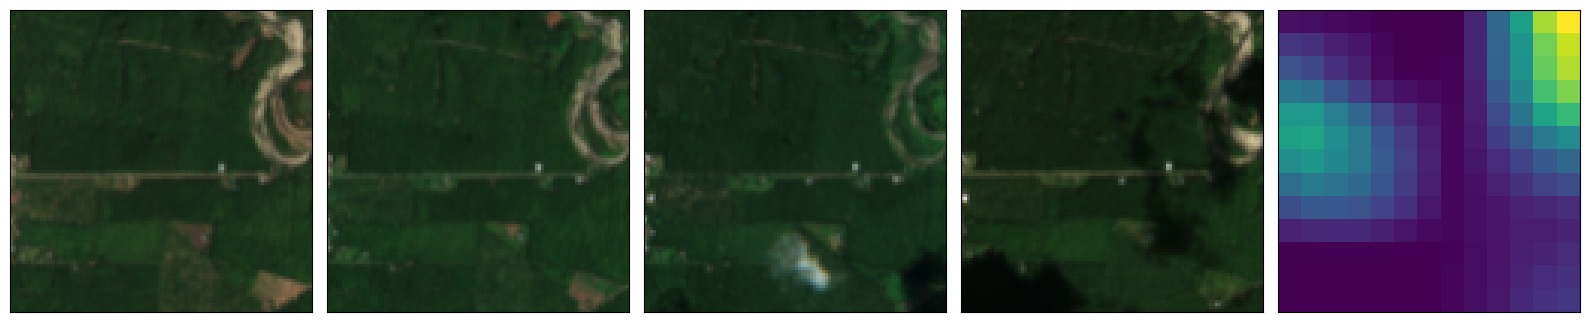

KeyboardInterrupt: Interrupted by user

In [86]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver != 'palm oil':
        continue
    i = row.name
    print(row)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expan
    sion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    pprint.pprint(rates)
    print()
    pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

In [118]:
palm_oil_sampleids = \
    [
        90042955,
        80103253,
        90042963
    ]


In [119]:
sampleid_ = palm_oil_sampleids[1]

In [120]:
#palm_oil_idx = 3531
palm_oil_idx = 3375 #80103253

In [122]:
_df_palm_oil = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == sampleid_])
_df_palm_oil = _df_palm_oil.reset_index(drop=True)


In [123]:
df_palm_oil = generate_random_points_df(_df_palm_oil)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 146.61it/s]


In [124]:
preds = []
for _i, row in tqdm.tqdm(df_palm_oil.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(palm_oil_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

1000it [00:22, 43.89it/s]


In [126]:
df_palm_oil

,driver,sampleid,dataset,country,geometry,block_id,split,dst_size,prediction,probability
0,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (18.225700145172084 4.970698778513906),203.0,val,NaN,4,0.958363
1,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (145.26351232196367 -17.831586247578713),203.0,val,NaN,4,0.906301
2,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (140.28276228485055 -2.901537132541737),203.0,val,NaN,4,0.974375
3,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (133.55573579734664 -13.424568068226652),203.0,val,NaN,4,0.855646
4,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (-39.900543724050294 -9.352120001084495),203.0,val,NaN,1,0.162433
...,...,...,...,...,...,...,...,...,...,...
995,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (-10.025594001874907 11.137425145043984),203.0,val,NaN,4,0.955374
996,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (29.687966794217772 -13.237149551476637),203.0,val,NaN,4,0.961816
997,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (29.35990205585267 -5.99571159239855),203.0,val,NaN,4,0.965815
998,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,POINT (44.726221314000014 -21.257441504292053),203.0,val,NaN,4,0.924288


In [127]:
df_palm_oil['prediction'] = torch.Tensor(np.array(preds)).argmax(dim=1)
df_palm_oil['probability'] = torch.Tensor(np.array(preds))[:,4]

In [128]:
gpd.GeoDataFrame(df_palm_oil).to_file(f'../data/tmp/palm_oil_{sampleid_}.gpkg')

In [129]:
sampleid_

80103253

## Cocoa

In [132]:
val_dl.dataset.img_labels.driver.unique()

array(['coffee', 'rubber', 'other', 'urban', 'mining',
       'shifting agriculture', 'soy', 'cocoa', 'palm oil', 'pasture',
       'forest plantation'], dtype=object)

driver                                              cocoa
sampleid                                         30002545
dataset                                         cocoa.csv
country                                             Ghana
geometry    POINT (-2.3694584203953237 6.705024433198755)
block_id                                            147.0
split                                                 val
dst_size                                              NaN
Name: 2326, dtype: object
{'cocoa': 2.28,
 'coffee': 0.0,
 'forest plantation': 0.0,
 'mining': nan,
 'other': nan,
 'palm oil': 0.16,
 'pasture': 0.26,
 'rubber': 0.11,
 'shifting agriculture': nan,
 'soy': 0.09,
 'urban': nan}

{'cocoa': 0.954,
 'coffee': 0.001,
 'forest plantation': 0.0,
 'mining': 0.0,
 'other': 0.0,
 'palm oil': 0.005,
 'pasture': 0.0,
 'rubber': 0.001,
 'shifting agriculture': 0.039,
 'soy': 0.0,
 'urban': 0.0}
cocoa


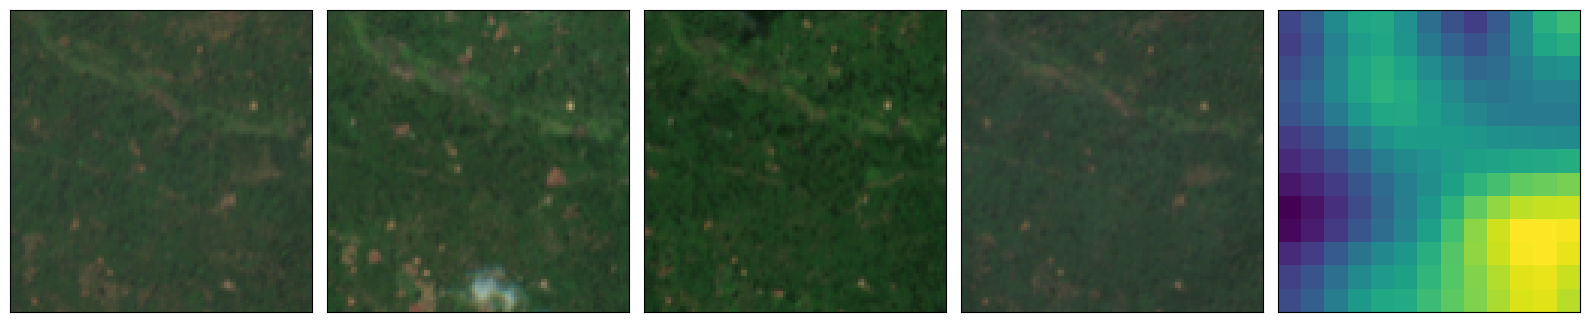

KeyboardInterrupt: Interrupted by user

In [143]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver != 'cocoa':
        continue
    i = row.name
    print(row)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    pprint.pprint(rates)
    print()
    pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

In [145]:
cocoa_sampleid = 30002545

In [146]:
_df_cocoa = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == cocoa_sampleid])
_df_cocoa

,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
2326,cocoa,30002545,cocoa.csv,Ghana,POINT (-2.36946 6.70502),147.0,val,NaN


In [147]:
_coco_idx = 2326

In [148]:
_df_cocoa = _df_cocoa.reset_index(drop=True)


In [151]:
df_cocoa = generate_random_points_df(_df_cocoa)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 143.55it/s]


In [152]:
preds = []
for _i, row in tqdm.tqdm(df_cocoa.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(_coco_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

1000it [00:22, 43.84it/s]


In [153]:
df_cocoa['prediction'] = torch.Tensor(np.array(preds)).argmax(dim=1)
df_cocoa['probability'] = torch.Tensor(np.array(preds))[:,7]
gpd.GeoDataFrame(df_cocoa).to_file(f'../data/tmp/cocoa_{cocoa_sampleid}.gpkg')

In [154]:
print(f'../data/tmp/cocoa_{cocoa_sampleid}.gpkg')

../data/tmp/cocoa_30002545.gpkg


### Soy

driver                                                 soy
sampleid                                          10615508
dataset                                      mapbiomas.csv
country                                             Brazil
geometry    POINT (-53.28109574819225 -13.001495904471813)
block_id                                              43.0
split                                                  val
dst_size                                               NaN
Name: 1957, dtype: object
{'cocoa': 0.0,
 'coffee': 0.01,
 'forest plantation': 0.01,
 'mining': nan,
 'other': nan,
 'palm oil': 0.0,
 'pasture': 3.05,
 'rubber': 0.0,
 'shifting agriculture': nan,
 'soy': 0.77,
 'urban': nan}

{'cocoa': 0.0,
 'coffee': 0.003,
 'forest plantation': 0.023,
 'mining': 0.001,
 'other': 0.044,
 'palm oil': 0.0,
 'pasture': 0.103,
 'rubber': 0.001,
 'shifting agriculture': 0.0,
 'soy': 0.825,
 'urban': 0.0}
soy


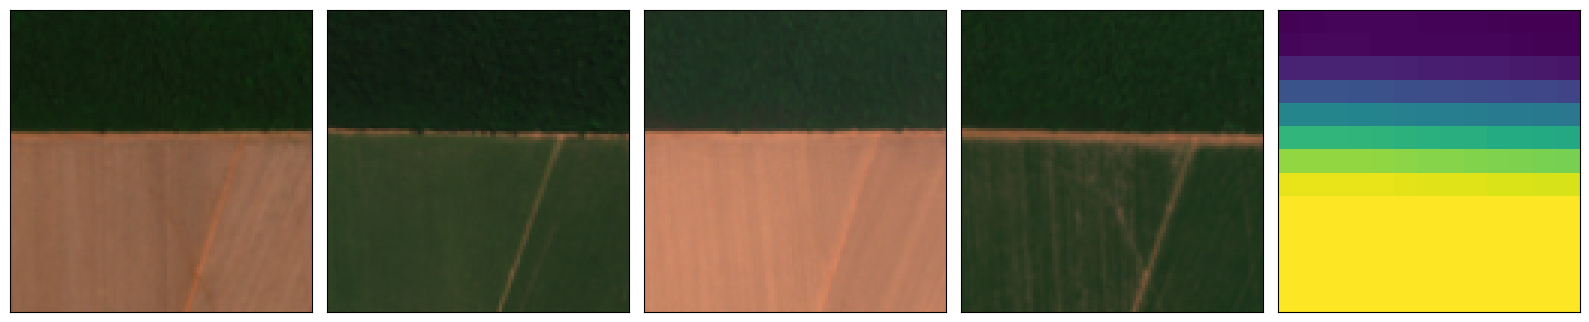

KeyboardInterrupt: Interrupted by user

In [193]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver != 'soy':
        continue
    i = row.name
    print(row)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    pprint.pprint(rates)
    print()
    pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

In [157]:
soy_sampleid = 150099711
#soy_sampleid = 10625677

In [158]:
_df_soy = pd.DataFrame(val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.sampleid == soy_sampleid])
_df_soy


,driver,sampleid,dataset,country,geometry,block_id,split,dst_size
1768,soy,150099711,soy_south_america.csv,Brazil,POINT (-52.28504 -17.24361),43.0,val,NaN


In [159]:
_soy_idx = 1768


In [160]:
_df_soy = _df_soy.reset_index(drop=True)


In [161]:
df_soy = generate_random_points_df(_df_soy)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:06<00:00, 156.55it/s]


In [162]:
preds = []
for _i, row in tqdm.tqdm(df_soy.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(_soy_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

1000it [00:22, 43.66it/s]


In [164]:
df_soy['prediction'] = torch.Tensor(np.array(preds)).argmax(dim=1)
df_soy['probability'] = torch.Tensor(np.array(preds))[:,2]
gpd.GeoDataFrame(df_soy).to_file(f'../data/tmp/soy_{soy_sampleid}.gpkg')

driver                                            coffee
sampleid                                       190000251
dataset                            manual_annotation.csv
country                                         Ethiopia
geometry    POINT (35.469560345379854 6.880993470519291)
block_id                                           154.0
split                                                val
Name: 96, dtype: object
PREDICTION:  coffee
coffee


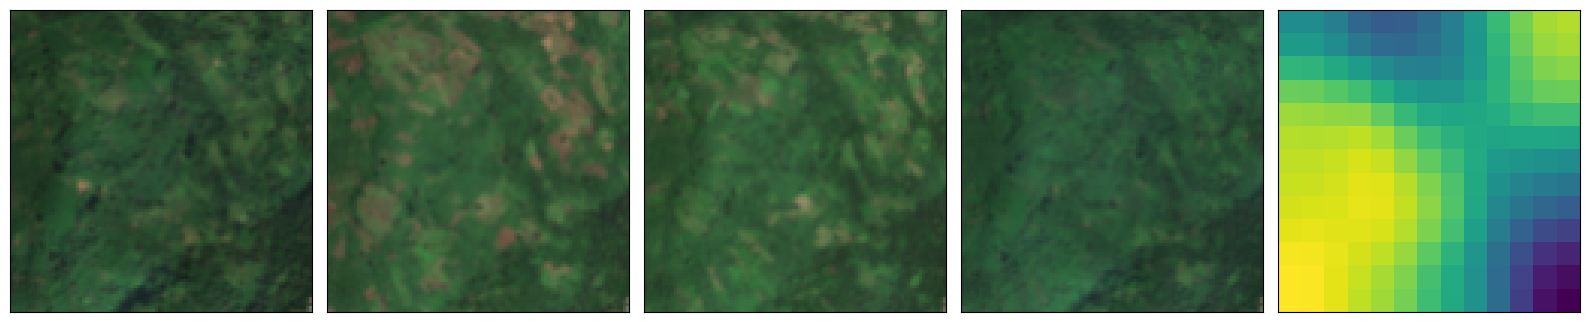

KeyboardInterrupt: Interrupted by user

In [57]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Ethiopia'].iterrows():
    i = row.name
    print(val_dl.dataset.img_labels.iloc[i])
    print('PREDICTION: ', xx.loc[xx.sampleid == row.sampleid].preds.values[0])
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

0